# ResNet-50 controlled hyperparameter experiments
Run all cells in order on BigMac. The grid compares learning rates [0.00001, 0.0001, 0.001], epochs [10, 100], class weighting [off, on], and threshold selection [fixed 0.5, validation recall target]. This produces 24 validation comparisons from six training runs using cached frozen ResNet-50 features.

Every run uses the same stratified split, initial classifier weights, and batch ordering. The baseline and one-change rows isolate individual changes. The full grid tests combinations. Fixed epoch checkpoints make the epoch comparison explicit.

Validation contains only 12 defects. Threshold tuning and model selection on this small set can overestimate performance. Only the selected configuration is evaluated on the official test set. That test set was inspected in earlier experiments, so these results remain exploratory.


## 1. Imports and settings

In [13]:
import csv
from itertools import product
from sklearn.metrics import confusion_matrix
import subprocess
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision.models import ResNet50_Weights, resnet50
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay,
)

SEED = 42
GPU_INDEX = 0
BATCH_SIZE = 16
EPOCH_OPTIONS = [10, 100]
LEARNING_RATES = [1e-5, 1e-4, 1e-3]
CLASS_WEIGHT_OPTIONS = [False, True]
THRESHOLD_OPTIONS = ["fixed", "validation_recall"]
VALIDATION_FRACTION = 0.2
TARGET_RECALL = 0.9
THRESHOLD = 0.5
ITEM = "candle"
DATA_DIR = Path("visa_data")
OUTPUT_DIR = Path("results/candle_resnet50")

torch.manual_seed(SEED)
if torch.cuda.is_available():
    assert GPU_INDEX < torch.cuda.device_count(), "Choose an available GPU index."
    device = torch.device(f"cuda:{GPU_INDEX}")
    for index in range(torch.cuda.device_count()):
        print(index, torch.cuda.get_device_name(index))
else:
    device = torch.device("cpu")
print("Using", device)


0 NVIDIA RTX A4500
1 NVIDIA RTX A4500
2 NVIDIA RTX A4500
3 NVIDIA RTX A4500
Using cuda:0


## 2. Load the data
The first run downloads the approximately 1.9 GB VisA archive if images are missing. Existing images are reused.

In [14]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

def download(url, destination):
    if destination.is_file():
        return
    partial = destination.with_suffix(destination.suffix + ".part")
    subprocess.run([
        "curl", "--fail", "--location", "--retry", "2",
        "--output", str(partial), url,
    ], check=True)
    partial.replace(destination)

split_file = DATA_DIR / "2cls_highshot.csv"
download("https://raw.githubusercontent.com/amazon-science/spot-diff/main/split_csv/2cls_highshot.csv", split_file)
with split_file.open(newline="") as file:
    rows = [row for row in csv.DictReader(file) if row["object"] == ITEM]
assert rows, "No images found for the selected product."

missing_images = {row["image"] for row in rows if not (DATA_DIR / row["image"]).is_file()}
if missing_images:
    archive = DATA_DIR / "VisA_20220922.tar"
    download("https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar", archive)
    with tarfile.open(archive) as tar:
        for member in tar:
            relative_path = Path(member.name)
            if str(relative_path) in missing_images and member.isfile():
                destination = (DATA_DIR / relative_path).resolve()
                assert DATA_DIR.resolve() in destination.parents
                destination.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as source, destination.open("wb") as target:
                    import shutil
                    shutil.copyfileobj(source, target)
assert all((DATA_DIR / row["image"]).is_file() for row in rows), "Some images are missing."
display(pd.crosstab(pd.DataFrame(rows)["split"], pd.DataFrame(rows)["label"]))


label,anomaly,normal
split,,
test,40,400
train,60,600


## 3. Prepare images and frozen features
The pretrained weights provide the image resizing and normalization. The encoder stays in evaluation mode to keep its batch normalization statistics fixed.

In [15]:
weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

class VisaDataset(Dataset):
    def __init__(self, split):
        self.examples = [row for row in rows if row["split"] == split]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        row = self.examples[index]
        with Image.open(DATA_DIR / row["image"]) as image:
            pixels = preprocess(image.convert("RGB"))
        label = torch.tensor({"normal": 0, "anomaly": 1}[row["label"]], dtype=torch.float32)
        return pixels, label

train_data = VisaDataset("train")
test_data = VisaDataset("test")
assert len(train_data) and len(test_data)
assert {r["image"] for r in train_data.examples}.isdisjoint(r["image"] for r in test_data.examples)

model = resnet50(weights=weights)
model.requires_grad_(False)
feature_count = model.fc.in_features
model.fc = nn.Identity()
encoder = model.to(device).eval()
classifier = nn.Linear(feature_count, 1).to(device)

@torch.no_grad()
def extract_features(dataset):
    features, labels = [], []
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    for images, targets in loader:
        features.append(encoder(images.to(device)).cpu())
        labels.append(targets)
    return TensorDataset(torch.cat(features), torch.cat(labels))

train_features = extract_features(train_data)
train_loader = DataLoader(train_features, batch_size=BATCH_SIZE, shuffle=True)
print("Training features", train_features.tensors[0].shape)


Training features torch.Size([660, 2048])


## 4. Compare individual changes and combinations
Compare the baseline with rows that change one setting. Use the full table to inspect interactions. Accuracy should be considered alongside missed defects and false alarms. Threshold changes affect decisions but leave average precision and ROC AUC unchanged for a given checkpoint.

Selection favors the fewest validation false alarms among runs reaching at least 90% recall, then higher average precision and fewer epochs. Training loss scales differ between weighted and unweighted runs.


Fit examples: 528 Validation examples: 132
Finished lr=1e-05, weighted=False, epoch=10
Finished lr=1e-05, weighted=False, epoch=100
Finished lr=1e-05, weighted=True, epoch=10
Finished lr=1e-05, weighted=True, epoch=100
Finished lr=0.0001, weighted=False, epoch=10
Finished lr=0.0001, weighted=False, epoch=100
Finished lr=0.0001, weighted=True, epoch=10
Finished lr=0.0001, weighted=True, epoch=100
Finished lr=0.001, weighted=False, epoch=10
Finished lr=0.001, weighted=False, epoch=100
Finished lr=0.001, weighted=True, epoch=10
Finished lr=0.001, weighted=True, epoch=100
Baseline and one-change experiments (validation results)


,learning_rate,weighted,epochs,threshold_mode,threshold,accuracy,recall,precision,average_precision,roc_auc,detected_defects,missed_defects,false_alarms,changes
0,0.0000,False,10,fixed,0.500,0.9091,0.0000,0.0000,0.0570,0.1764,0,12,0,0
1,0.0000,False,10,validation_recall,0.408,0.0985,0.9167,0.0853,0.0570,0.1764,11,1,118,1
2,0.0000,False,100,fixed,0.500,0.9091,0.0000,0.0000,0.0653,0.2889,0,12,0,1
4,0.0000,True,10,fixed,0.500,0.0909,1.0000,0.0909,0.1135,0.3625,12,0,120,1
8,0.0001,False,10,fixed,0.500,0.9091,0.0000,0.0000,0.0639,0.2729,0,12,0,1
16,0.0010,False,10,fixed,0.500,0.9091,0.0000,0.0000,0.8359,0.9708,0,12,0,1


All combinations (validation results)


,learning_rate,weighted,epochs,threshold_mode,threshold,accuracy,recall,precision,average_precision,roc_auc,detected_defects,missed_defects,false_alarms,changes
12,0.0001,True,10,fixed,0.5000,0.6970,1.0000,0.2308,0.7619,0.9382,12,0,40,2
4,0.0000,True,10,fixed,0.5000,0.0909,1.0000,0.0909,0.1135,0.3625,12,0,120,1
11,0.0001,False,100,validation_recall,0.1334,0.9167,0.9167,0.5238,0.8563,0.9743,11,1,10,3
17,0.0010,False,10,validation_recall,0.1336,0.9167,0.9167,0.5238,0.8359,0.9708,11,1,10,2
15,0.0001,True,100,validation_recall,0.5193,0.9091,0.9167,0.5000,0.8418,0.9681,11,1,11,4
21,0.0010,True,10,validation_recall,0.5217,0.9091,0.9167,0.5000,0.8418,0.9681,11,1,11,3
23,0.0010,True,100,validation_recall,0.2494,0.9091,0.9167,0.5000,0.8915,0.9792,11,1,11,4
19,0.0010,False,100,validation_recall,0.0709,0.9015,0.9167,0.4783,0.8924,0.9799,11,1,12,3
14,0.0001,True,100,fixed,0.5000,0.8939,0.9167,0.4583,0.8418,0.9681,11,1,13,3
20,0.0010,True,10,fixed,0.5000,0.8939,0.9167,0.4583,0.8418,0.9681,11,1,13,2


Selected experiment for test evaluation


,Selected value
learning_rate,0.0001
weighted,False
epochs,100
threshold_mode,validation_recall
threshold,0.133378
accuracy,0.916667
recall,0.916667
precision,0.52381
average_precision,0.85632
roc_auc,0.974306


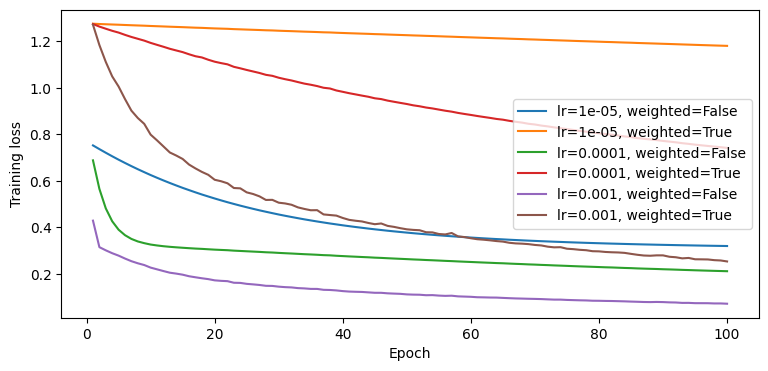

In [16]:
# Every experiment uses the same split, initialization, and batch ordering.
features, labels = train_features.tensors
train_indices, validation_indices = train_test_split(
    range(len(labels)), test_size=VALIDATION_FRACTION,
    stratify=labels.numpy(), random_state=SEED,
)
fit_features = features[train_indices].to(device)
fit_labels = labels[train_indices].to(device)
validation_features = features[validation_indices].to(device)
validation_labels = labels[validation_indices].numpy().astype(int)
class_ratio = (fit_labels == 0).sum() / (fit_labels == 1).sum()
print("Fit examples:", len(train_indices), "Validation examples:", len(validation_indices))

experiment_rows = []
history_rows = []
model_states = {}

# Train each learning-rate/weighting pair once. Save exact epoch checkpoints.
for learning_rate, weighted in product(LEARNING_RATES, CLASS_WEIGHT_OPTIONS):
    torch.manual_seed(SEED)
    classifier = nn.Linear(feature_count, 1).to(device)
    generator = torch.Generator().manual_seed(SEED)
    fit_loader = DataLoader(
        TensorDataset(fit_features, fit_labels), batch_size=BATCH_SIZE,
        shuffle=True, generator=generator,
    )
    positive_weight = class_ratio if weighted else torch.tensor(1.0, device=device)
    loss_function = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=learning_rate, weight_decay=1e-4)
    for epoch in range(1, max(EPOCH_OPTIONS) + 1):
        classifier.train()
        total_loss = 0.0
        for batch_features, batch_labels in fit_loader:
            optimizer.zero_grad()
            logits = classifier(batch_features).squeeze(1)
            loss = loss_function(logits, batch_labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_labels)
        history_rows.append({
            "learning_rate": learning_rate, "weighted": weighted,
            "epoch": epoch, "train_loss": total_loss / len(train_indices),
        })
        if epoch not in EPOCH_OPTIONS:
            continue
        classifier.eval()
        with torch.no_grad():
            scores = classifier(validation_features).squeeze(1).sigmoid().cpu().numpy()
        checkpoint = (learning_rate, weighted, epoch)
        model_states[checkpoint] = {
            name: value.detach().cpu().clone()
            for name, value in classifier.state_dict().items()
        }
        for threshold_mode in THRESHOLD_OPTIONS:
            threshold = 0.5
            if threshold_mode == "validation_recall":
                # The highest threshold meeting the recall target minimizes false alarms.
                candidates = sorted(set(scores), reverse=True)
                threshold = next(
                    float(value) for value in candidates
                    if recall_score(validation_labels, scores >= value) >= TARGET_RECALL
                )
            predicted = (scores >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(validation_labels, predicted, labels=[0, 1]).ravel()
            experiment_rows.append({
                "learning_rate": learning_rate, "weighted": weighted,
                "epochs": epoch, "threshold_mode": threshold_mode,
                "threshold": threshold,
                "accuracy": accuracy_score(validation_labels, predicted),
                "recall": recall_score(validation_labels, predicted, zero_division=0),
                "precision": precision_score(validation_labels, predicted, zero_division=0),
                "average_precision": average_precision_score(validation_labels, scores),
                "roc_auc": roc_auc_score(validation_labels, scores),
                "detected_defects": tp, "missed_defects": fn, "false_alarms": fp,
            })
        print(f"Finished lr={learning_rate:g}, weighted={weighted}, epoch={epoch}")

experiments = pd.DataFrame(experiment_rows)
# Count changes relative to the original 10-epoch, unweighted, 1e-5, 0.5 setup.
experiments["changes"] = (
    experiments.learning_rate.ne(1e-5).astype(int)
    + experiments.weighted.astype(int)
    + experiments.epochs.ne(10).astype(int)
    + experiments.threshold_mode.ne("fixed").astype(int)
)
print("Baseline and one-change experiments (validation results)")
display(experiments[experiments.changes <= 1].sort_values("changes").round(4))
print("All combinations (validation results)")
display(experiments.sort_values(["missed_defects", "false_alarms"]).round(4))

# Select among runs meeting the recall target, favoring fewer false alarms.
eligible = experiments[experiments.recall >= TARGET_RECALL]
selected = eligible.sort_values(
    ["false_alarms", "average_precision", "epochs"], ascending=[True, False, True],
).iloc[0]
best_learning_rate = float(selected.learning_rate)
best_epoch = int(selected.epochs)
selected_weighted = bool(selected.weighted)
THRESHOLD = float(selected.threshold)
positive_weight = class_ratio if selected_weighted else torch.tensor(1.0, device=device)
classifier.load_state_dict(model_states[(best_learning_rate, selected_weighted, best_epoch)])
classifier.eval()
history = pd.DataFrame(history_rows)
print("Selected experiment for test evaluation")
display(selected.to_frame("Selected value"))

fig, axis = plt.subplots(figsize=(9, 4))
for (learning_rate, weighted), run in history.groupby(["learning_rate", "weighted"]):
    axis.plot(run.epoch, run.train_loss, label=f"lr={learning_rate:g}, weighted={weighted}")
axis.set(xlabel="Epoch", ylabel="Training loss")
axis.legend()
plt.show()


## 5. Evaluate the test set
Recall measures how many defects we catch. Precision measures how often a predicted defect is correct. Average precision and ROC AUC evaluate the probability ranking across thresholds.

,accuracy,average_precision,roc_auc,precision,recall,f1
ResNet-50,0.9182,0.7382,0.9361,0.5345,0.775,0.6327


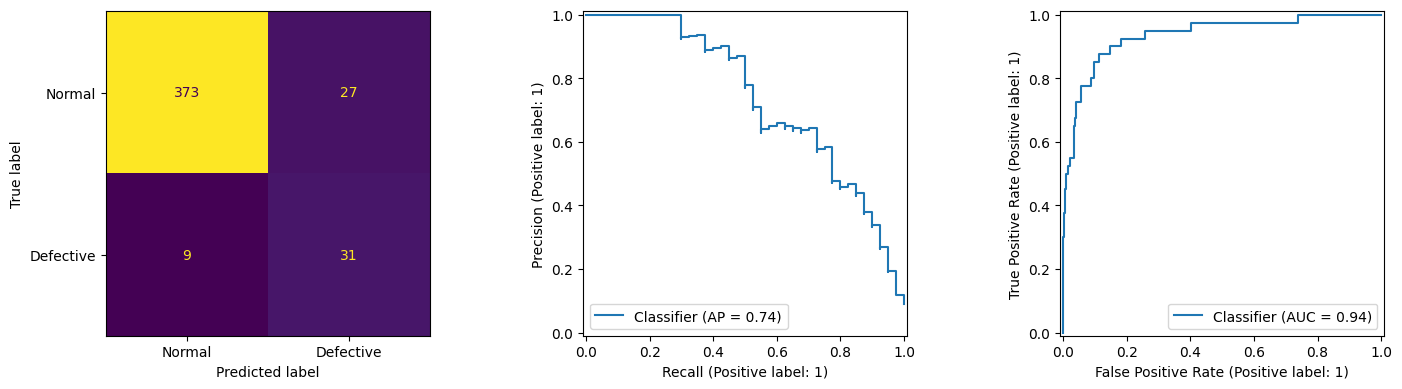

Missed defects 9


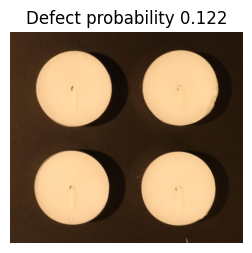

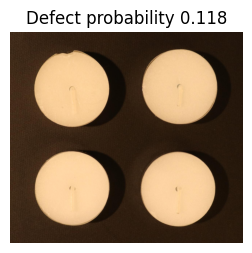

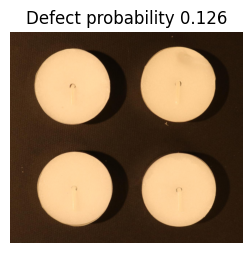

False alarms 27


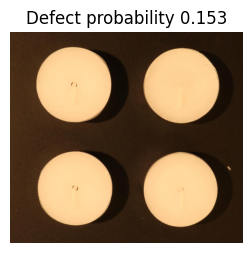

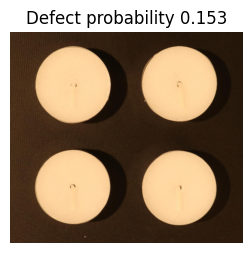

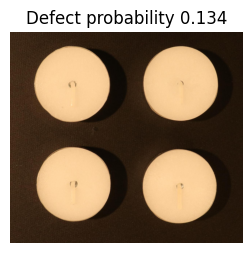

In [17]:
test_features = extract_features(test_data)
classifier.eval()
with torch.no_grad():
    probabilities = classifier(test_features.tensors[0].to(device)).squeeze(1).sigmoid().cpu().numpy()
actual = test_features.tensors[1].numpy().astype(int)
predicted = (probabilities >= THRESHOLD).astype(int)
assert len(set(actual)) == 2, "Both classes are needed for ROC AUC."
metrics = {
    "accuracy": accuracy_score(actual, predicted),
    "average_precision": average_precision_score(actual, probabilities),
    "roc_auc": roc_auc_score(actual, probabilities),
    "precision": precision_score(actual, predicted, zero_division=0),
    "recall": recall_score(actual, predicted, zero_division=0),
    "f1": f1_score(actual, predicted, zero_division=0),
}
display(pd.DataFrame([metrics], index=["ResNet-50"]).round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=[0, 1], display_labels=["Normal", "Defective"], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(actual, probabilities, ax=axes[1])
RocCurveDisplay.from_predictions(actual, probabilities, ax=axes[2])
plt.tight_layout()
plt.show()

predictions = pd.DataFrame({
    "image": [row["image"] for row in test_data.examples],
    "label": actual, "probability": probabilities, "prediction": predicted,
})
for title, mistakes in [
    ("Missed defects", predictions[(predictions.label == 1) & (predictions.prediction == 0)]),
    ("False alarms", predictions[(predictions.label == 0) & (predictions.prediction == 1)]),
]:
    print(title, len(mistakes))
    for row in mistakes.head(3).itertuples():
        with Image.open(DATA_DIR / row.image) as image:
            plt.figure(figsize=(3, 3))
            plt.imshow(image)
            plt.title(f"Defect probability {row.probability:.3f}")
            plt.axis("off")
            plt.show()


## 6. Save and compare
Outputs are saved when this cell runs. The comparison uses the last epoch from the existing ResNet-18 results, if available. Confirm that those results use the same candle split before interpreting the comparison.
The ResNet-18 comparison is the earlier baseline. Training settings and the amount of training data differ in this experiment. Running this cell replaces the previous ResNet-50 result files.


In [18]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
experiments.to_csv(OUTPUT_DIR / "validation_experiments.csv", index=False)
history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
torch.save({
    "classifier_state_dict": classifier.state_dict(),
    "weights": str(weights), "threshold": THRESHOLD,
    "seed": SEED, "epochs": best_epoch, "learning_rate": best_learning_rate, "selected_epoch": best_epoch,
    "validation_fraction": VALIDATION_FRACTION, "target_recall": TARGET_RECALL,
    "positive_weight": float(positive_weight.item()),
}, OUTPUT_DIR / "classifier.pt")
comparison = pd.DataFrame([metrics], index=["ResNet-50"])
baseline_path = Path("results/candle_resnet18/epoch_metrics.csv")
if baseline_path.is_file():
    baseline = pd.read_csv(baseline_path).iloc[-1]
    comparison.loc["ResNet-18"] = baseline.reindex(comparison.columns)
display(comparison.round(4))


,accuracy,average_precision,roc_auc,precision,recall,f1
ResNet-50,0.9182,0.7382,0.9361,0.5345,0.775,0.6327
ResNet-18,0.9091,0.0890,0.4441,NaN,0.000,0.0000
